# 2η Ατομική εργασία

#### Δημήτριος Μιχαλακόπουλος
#### ΑΜ: 03120229



# Θεωρητικό Μέρος

**Αφού μελετήσετε τα σχετικά άρθρα κάθως και τις υλοποιήσεις τους, παρουσιάστε ένα συγκριτικό πίνακα με τα επίπεδα, το μέγεθος των φίλτρων, τη συνάρτηση ενεργοποίησης, το πλήθος παραμέτρων και τεχνικές pooling και dropout που χρησιμοποιούν τα 3 διαφορετικά δίκτυα που παρουσιάζονται στα προαναφερθέντα άρθρα και σχολιάστε ως προς την απόδοση τους.**

Η απόδοση κάθε φίλτρου σε ένα Convolutional Neural Network  (CNN) επηρεάζεται από διάφορους παράγοντες, όπως τα επίπεδα των συνελικτικών στρωμάτων, το μέγεθος των φίλτρων, η επιλογή των συναρτήσεων ενεργοποίησης και η εφαρμογή τεχνικών pooling  και dropout.

Η LeNet, ως μια από τις πρωτοποριακές αρχιτεκτονικές του CNN, εισήγαγε την εφαρμογή των CNN για εργασίες όπως η χειρόγραφη αναγνώριση ψηφίων. Αν και ήταν επαναστατικό στην εποχή του, η απόδοσή του μπορεί να μην ταιριάζει με αυτή των πιο πρόσφατων αρχιτεκτονικών όπως το AlexNet και το VGG, ιδιαίτερα όταν πρόκειται για πιο σύνθετα σύνολα δεδομένων όπως το ImageNet.

Το AlexNet, μια άλλη πρωτοποριακή αρχιτεκτονική, έκανε σημαντικά βήματα στο ImageNet Large-Scale Visual Recognition Challenge (ILSVRC), μειώνοντας κυρίως το ποσοστό σφαλμάτων κορυφαίων 5 (top-5) προβλέψεων σε σύγκριση με προηγούμενες προσεγγίσεις. Η επιτυχία του έπαιξε καθοριστικό ρόλο στη διάδοση των βαθιών συνελικτικών νευρωνικών δικτύων για εργασίες ταξινόμησης εικόνων.

Το VGG, από την άλλη πλευρά, έφερε επανάσταση στην αρχιτεκτονική υποστηρίζοντας τη χρήση πολλαπλών επιπέδων με μικρότερα μεγέθη φίλτρων (συνήθως συνελίξεις $3x3$) διατεταγμένα σε μπλοκ. Αυτή η προσέγγιση, η οποία οδήγησε σε βαθύτερες αρχιτεκτονικές, αποδείχθηκε εξαιρετικά αποτελεσματική, με το VGG να επιτυγχάνει κορυφαία απόδοση στο σύνολο δεδομένων ImageNet.

|Network|Layers|Filter Size|Activation Function|Parameters|Pooling|Dropout|
|:---   |:---  |:---       |:---               |:---      |:---   |:---   |
| LeNet | 7 (C1, S2, C3, S4, F5, F6, Output) | 5×5 (conv), 2×2 (pool) | tan(h) | ~60,000 | Average | No |
| AlexNet | 8 (5 conv + 3 FC) | 11×11, 5×5, 3×3 (conv), 3×3 (pool) | ReLU | 62,378,344 | Max | Yes |
| VGG | Variable (11–19 layers) | 3×3 (conv), 2×2 (pool) | ReLU | Varies (133-144 Million) | Max | Yes |

Αξίζει να σχολιαστεί πώς καθένα από τα στοιχεία του παραπάνω πίνακα επηρεάζουν την απόδοση κάθε δικτύου.

#### 1. Layers

- **LeNet** : Το LeNet περιλαμβάνει 7 επίπεδα:
  1. Δύο συνελικτικά επίπεδα
  2. Aκολουθούν δύο στρώματα υποδειγματοληψίας (pooling)
  3. Και τέλος, τρία πλήρως συνδεδεμένα στρώματα.

Αν και θεωρήθηκε βαθύ κατά την έναρξή του, φαίνεται σχετικά ρηχό σε σύγκριση με σύγχρονες αρχιτεκτονικές όπως το AlexNet και το VGG.

- **AlexNet** : Το AlexNet αποτελείται από:
  1. Πέντε συνελικτικά επίπεδα
  2. Και ακολουθούν 3 πλήρως συνδεδεμένα επίπεδα

Αυτό το βάθος του επιτρέπει να μαθαίνει ιεραρχικά χαρακτηριστικά από ακατέργαστα pixel, συμβάλλοντας στην καλύτερη εκμάθηση αναπαράστασης.

- **VGG**: Το VGG προσφέρει διάφορες διαμορφώσεις με βάθη που κυμαίνονται συνήθως από 11 έως 19 επίπεδα. Οι βαθύτερες αρχιτεκτονικές του διευκολύνουν την εκμάθηση πιο περίπλοκων χαρακτηριστικών και τη βελτιωμένη αναπαράσταση των ιεραρχικών χαρακτηριστικών, βελτιώνοντας έτσι την απόδοση του δικτύου.


#### 2. Filter Size

-**LeNet** : Χρησιμοποιούνται κυρίως μικρότερα μεγέθη φίλτρων, όπως το $5x5$ στα convolutional layers του. Τα μικρότερα μεγέθη φίλτρων επιτρέπουν στο δίκτυο να καταγράφει τις πιο λεπτές λεπτομέρειες και τις άκρες των εικόνων εισόδου.

-**AlexNet** : Χρησιμοποιούνται μεγάλα μεγέθη φίλτρων, όπως $11x11$ και $5x5$ στα πρώτα του στρώματα. Αυτά τα μεγαλύτερα φίλτρα βοηθούν στην αντίληψη ευρύτερων μοτίβων και χωρικών πληροφοριών στις εικόνες εισόδου.

-**VGG** : Χρησιμοποιούνται μεγέθη φίλτρων $3x3$ σε όλη την αρχιτεκτονική του. Η χρήση μικρότερων μεγεθών φίλτρου βοηθά στην εκμάθηση πιο περίπλοκων και αφηρημένων χαρακτηριστικών, διατηρώντας παράλληλα των αριθμό των παραμέτρων διαχειρίσιμο.

#### 3. Activation Function

-**LeNet** : Η συνάρτηση ενεργοποίησης είναι αυτή της υπερβολικής εφαπτομένεης ($tan(h)$), η οποία ήταν κοινή σε παλαιότερες αρχιτεκτονικές νευρωνικών δικτύων. Ενώ είναι αποτελεσματικό, το $tan(h)$ τείνει να κορεστεί για ακραίες τιμές εισόδου, οδηγώντας σε πιο αργή σύγκλιση. Στην υλοποίηση μας και στα παραδείγματα που μας δόθηκαν από το εργαστήριο, χρησιμοποιούμε την $sigmoid$ activation function.

-**AlexNet και VGG** : Η συνάρτηση ενεργοποίησης, Rectified Linear Unit (ReLU), έχει αποδειχθεί ότι επιταχύνει τη σύγκλιση της στοχαστικής κλίσης κατά τη διάρκεια του training και αποτρέπει το vanishing gradient problem.


#### 4. Parameters

-**LeNet** : Με περίπου 60.000 παραμέτρους, το δίκτυο LeNet διαθέτει σημαντικά χαμηλότερο αριθμό παραμέτρων σε σύγκριση με τα πιο σύγχρονα αντίστοιχα. Αυτό το χαρακτηριστικό το καθιστά πιο κατάλληλο για απλούστερες εργασίες και σύνολα δεδομένων με λιγότερα δείγματα.

-**AlexNet** : Με περισσότερες από 62 εκατομμύρια παραμέτρους, το AlexNet αναδεικνύεται ως ένα από τα μεγαλύτερα και πιο περίπλοκα μοντέλα της εποχής του. Η αφθονία των παραμέτρων το εξοπλίζει για να διακρίνει περίπλοκα χαρακτηριστικά μέσα στα δεδομένα εισόδου. Ωστόσο, αυτή η αφθονία αυξάνει επίσης τον κίνδυνο υπερβολικής προσαρμογής, ιδιαίτερα όταν εργάζεστε με μικρότερα σύνολα δεδομένων.

-**VGG** : Ο αριθμός παραμέτρων του VGG ποικίλλει ανάλογα με τη συγκεκριμένη αρχιτεκτονική που χρησιμοποιείται, αλλά τυπικά κυμαίνεται από περίπου 133 εώς 144 εκατομμύρια. Οι βαθύτερες αρχιτεκτονικές του VGG απαιτούν μεγαλύτερο αριθμό παραμέτρων, επιτρέποντάς του να μαθαίνει από πιο περίπλοκες αναπαραστάσεις δεδομένων.

#### 5. Pooling

-**LeNet** : Χρησιμοποιώντας μια στρατηγική μέτριας συγκέντρωσης, το LeNet χρησιμοποιεί average pooling layers για να μειώσει τις χωρικές διαστάσεις των χαρτών χαρακτηριστικών. Αυτή η τεχνική υπολογίζει τον μέσο όρο κάθε χάρτη χαρακτηριστικών, με αποτέλεσμα μια πιο ομαλή αναπαράσταση των δεδομένων εισόδου.

-**AlexNet και VGG** : Αντίθετα, τόσο το AlexNet όσο και το VGG χρησιμοποιούν επίπεδα max-pooling για να υποδείξουν χάρτες χαρακτηριστικών και να μειώσουν τις χωρικές διαστάσεις διατηρώντας παράλληλα τα κρίσιμα χαρακτηριστικά. Το Max-pooling είναι αποφασιστικό για την εισαγωγή της μεταβλητότητας της μετάφρασης και την αποτελεσματική διαχείριση της υπολογιστικής πολυπλοκότητας.


#### 6. Dropout

-**LeNet** : Σε αντίθεση με το AlexNet και το VGG, το LeNet δεν ενσωματώνει ρητά την τακτική dropout. Αυτή η απουσία εγκατάλειψης μπορεί να καταστήσει το LeNet πιο επιρρεπές στην υπερπροσαρμογή (overfitting), ιδιαίτερα όταν εκπαιδεύεται σε μεγαλύτερα σύνολα δεδομένων.

-**AlexNet και VGG** : Αντίθετα, τόσο το AlexNet όσο και το VGG ενσωματώνουν το dropout στα πλήρως συνδεδεμένα επίπεδα. Το Dropout απενεργοποιεί τυχαία ένα τμήμα νευρώνων κατά τη διάρκεια της εκπαίδευσης, αναγκάζοντας το δίκτυο να μάθει από διαφορετικές περιττές αναπαραστάσεις. Αυτή η τεχνική ενισχύει την ευρωστία του δικτύου, μετριάζει την υπερπροσαρμογή και ενθαρρύνει την ανακάλυψη πιο γενικευμένων χαρακτηριστικών.



#Υλοποίηση αλγορίθμου

## Εισαγωγή και επισκόπηση του συνόλου δεδομένων

In [1]:
from __future__ import absolute_import, division, print_function, unicode_literals # legacy compatibility

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# helper functions

# select from from_list elements with index in index_list
def select_from_list(from_list, index_list):
  filtered_list= [from_list[i] for i in index_list]
  return(filtered_list)

# append in filtered_list the index of each element of unfilterd_list if it exists in in target_list
def get_ds_index(unfiliterd_list, target_list):
  index = 0
  filtered_list=[]
  for i_ in unfiliterd_list:
    if i_[0] in target_list:
      filtered_list.append(index)
    index += 1
  return(filtered_list)


In [3]:
# load the entire dataset
import tensorflow as tf
from tensorflow.keras import datasets, layers, models

(x_train_all, y_train_all), (x_test_all, y_test_all) = tf.keras.datasets.cifar100.load_data(label_mode='fine')


169001437/169001437 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [4]:
print(x_train_all.shape)

(50000, 32, 32, 3)


Η κάθε ομάδα θα δουλέψει με διαφορετικό υποσύνολο του dataset.
Στο επόμενο κελί, αντικαταστήστε την τιμή της μεταβλητής `team_seed` με τον αριθμό που αντιστοιχεί στην ομάδας σας.

In [5]:
# REPLACE WITH YOUR TEAM NUMBER
team_seed = 29
classes_num = 20

In [6]:
# select from CIFAR100 20 classes
cifar100_classes_url = "https://pastebin.com/raw/nzE1n98V"

Δημιουργούμε το μοναδικό dataset της ομάδας μας:

In [7]:
team_classes = pd.read_csv('team_classes.csv', sep=',', header=None)
CIFAR100_LABELS_LIST = pd.read_csv('cifar100_labels.csv', sep=',', header=None).astype(str).values.tolist()[0]

our_index = team_classes.iloc[team_seed,:].values.tolist()
our_classes = select_from_list(CIFAR100_LABELS_LIST, our_index)
train_index = get_ds_index(y_train_all, our_index)
test_index = get_ds_index(y_test_all, our_index)

x_train_ds = np.asarray(select_from_list(x_train_all, train_index))
y_train_ds = np.asarray(select_from_list(y_train_all, train_index))
x_test_ds = np.asarray(select_from_list(x_test_all, test_index))
y_test_ds = np.asarray(select_from_list(y_test_all, test_index))

In [8]:
# print our classes
print(our_classes)

[' bee', ' bowl', ' caterpillar', ' clock', ' dinosaur', ' dolphin', ' fox', ' hamster', ' maple_tree', ' mountain', ' pickup_truck', ' porcupine', ' rabbit', ' sea', ' shrew', ' sweet_pepper', ' table', ' television', ' train', ' worm']


In [9]:
print(x_train_ds[1].shape)

(32, 32, 3)


Train: X=(8500, 32, 32, 3), y=(8500, 1)
Validation: X=(1500, 32, 32, 3), y=(1500, 1)
Test: X=(2000, 32, 32, 3), y=(2000, 1)


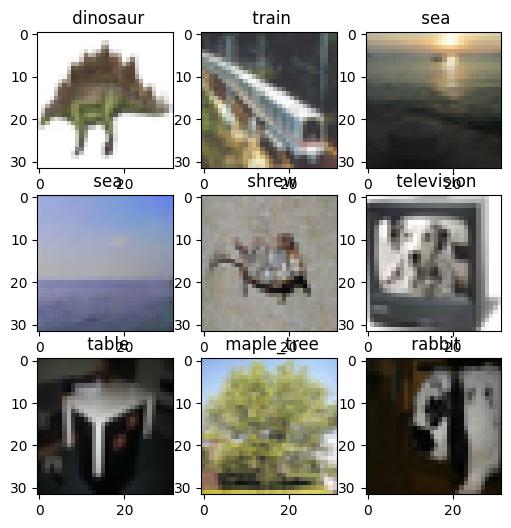

In [10]:
# get (train) dataset dimensions
data_size, img_rows, img_cols, img_channels = x_train_ds.shape

# set validation set percentage (wrt the training set size)
validation_percentage = 0.15
val_size = round(validation_percentage * data_size)

# Reserve val_size samples for validation and normalize all values
x_val = x_train_ds[-val_size:]/255
y_val = y_train_ds[-val_size:]
x_train = x_train_ds[:-val_size]/255
y_train = y_train_ds[:-val_size]
x_test = x_test_ds/255
y_test = y_test_ds

# summarize loaded dataset
print('Train: X=%s, y=%s' % (x_train.shape, y_train.shape))
print('Validation: X=%s, y=%s' % (x_val.shape, y_val.shape))
print('Test: X=%s, y=%s' % (x_test.shape, y_test.shape))

# print("Type of x_train:", x_train.dtype)
# print("Type of y_train:", y_train.dtype)
# print("Type of x_test:", x_test.dtype)
# print("Type of y_test:", y_test.dtype)

# get class label from class index
def class_label_from_index(fine_category):
  return(CIFAR100_LABELS_LIST[fine_category.item(0)])

# plot first few images
plt.figure(figsize=(6, 6))
for i in range(9):
	# define subplot
  plt.subplot(330 + 1 + i).set_title(class_label_from_index(y_train[i]))
	# plot raw pixel data
  plt.imshow(x_train[i], cmap=plt.get_cmap('gray'))
  #show the figure
plt.show()

## Ερώτημα 1
---
### Βήμα 1: Σχεδίαση και εκπαίδευση των μοντέλων

 Σχεδίαστε και εκπαιδεύστε τα μοντέλα  **LeNet, AlexNet και  VGG**, καθώς και ένα δικό σας μοντέλο (ονομάστε το π.χ. **MyCNN**) χρησιμοποιώντας τον ίδιο αλγορίθμο βελτιστοποίησης ([optimizer](https://keras.io/api/optimizers/)), την ίδια συνάρτηση κόστους [loss function](https://keras.io/api/losses/), το ίδιο μέγεθος παρτίδας (batch size) και 50 εποχές (epochs) `*`.

 Για την εκτίμηση της απόδοσης των μοντέλων να χρησιμοποιήσετε ως μετρική ([metrics](https://keras.io/api/metrics/)) την F1-score.


`*`
 Μπορείτε να πειραματιστείτε με τον optimizer, την loss function και το batch size για τα 4 μοντέλα πριν καταλήξετε στην τελική σας κοινή, για όλα τα μοντέλα επιλογή.

---


In [11]:
import numpy as np

def map_labels(labels):
    unique_labels = np.unique(labels)
    label_dict = {label.item(): idx for idx, label in enumerate(unique_labels)}
    return [label_dict[label.item()] for label in labels], label_dict

# Mapping training, testing, and validation labels
y_train_mapped, label_dict = map_labels(y_train)
y_test_mapped = [label_dict[label.item()] for label in y_test]
y_val_mapped = [label_dict[label.item()] for label in y_val]

# Converting to numpy arrays
y_train_mapped = np.array([[label] for label in y_train_mapped])
y_test_mapped = np.array([[label] for label in y_test_mapped])
y_val_mapped = np.array([[label] for label in y_val_mapped])


### Le Net

In [13]:
from tensorflow.keras.metrics import F1Score
import tensorflow as tf
from tensorflow.keras import layers, models, losses
from sklearn.metrics import f1_score
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.metrics import Precision, Recall


# Define LeNet model
def LeNet(input_shape, num_classes):
    model = models.Sequential([
        layers.Conv2D(6, kernel_size=5, activation='sigmoid', input_shape=input_shape),
        layers.AveragePooling2D(pool_size=2, strides=2),
        layers.Conv2D(16, kernel_size=5, activation='sigmoid'),
        layers.AveragePooling2D(pool_size=2, strides=2),
        layers.Flatten(),
        layers.Dense(120, activation='sigmoid'),
        layers.Dense(84, activation='sigmoid'),
        layers.Dense(num_classes, activation='softmax')
    ], name='LeNet')
    return model

LeNetModel = LeNet((32, 32, 3), classes_num)

# Print LeNet Model Summary
print("LeNet Model Summary:")
LeNetModel.summary()

y_train_mapped_onehot = to_categorical(y_train_mapped, classes_num)
y_val_mapped_onehot = to_categorical(y_val_mapped, classes_num)

# Compile the model with F1 score metric
f1_score_metric = F1Score(average='macro') # You can adjust 'average' as per your requirement
LeNetModel.compile(optimizer='adam',
                   loss='categorical_crossentropy',
                   metrics=[f1_score_metric])

print("Training LeNet Model ...")

# Train the model
LeNetHistory = LeNetModel.fit(x_train, y_train_mapped_onehot,
                              batch_size=128,
                              epochs=50,
                              validation_data=(x_val, y_val_mapped_onehot),
                              verbose=1)



LeNet Model Summary:


Model: "LeNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │         1,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,856 (245.53 KB)

 Trainable params: 62,856 (245.53 KB)

 Non-trainable params: 0 (0.00 B)

Training LeNet Model ...
Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - f1_score: 0.0194 - loss: 3.0356 - val_f1_score: 0.0051 - val_loss: 3.0008
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - f1_score: 0.0190 - loss: 3.0009 - val_f1_score: 0.0046 - val_loss: 2.9843
Epoch 3/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - f1_score: 0.0437 - loss: 2.9386 - val_f1_score: 0.0700 - val_loss: 2.8054
Epoch 4/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - f1_score: 0.0871 - loss: 2.7567 - val_f1_score: 0.1033 - val_loss: 2.6959
Epoch 5/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - f1_score: 0.1210 - loss: 2.6523 - val_f1_score: 0.1125 - val_loss: 2.6341
Epoch 6/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - f1_score: 0.1296 - loss: 2.5994 - val_f1_score: 0.1314 - val_loss: 2.5771
Epoch 7/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - f1_score: 0.1460 - loss: 2.5324 - val_f1_score: 0.1529 - val_loss: 2.5343
Epoch 8/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - f1_score: 0.1668 - loss: 2.4665 - val_f1

###AlexNet

In [15]:
import tensorflow as tf
from tensorflow.keras import layers, models, losses
from sklearn.metrics import f1_score

# Define AlexNet model
def AlexNet(input_shape, num_classes):
    model = models.Sequential([
        layers.Conv2D(96, kernel_size=3, strides=1, activation='relu', input_shape=input_shape),
        layers.MaxPool2D(pool_size=3, strides=2),
        layers.Conv2D(256, kernel_size=3, padding='same', activation='relu'),
        layers.MaxPool2D(pool_size=3, strides=2),
        layers.Conv2D(384, kernel_size=3, padding='same', activation='relu'),
        layers.Conv2D(384, kernel_size=3, padding='same', activation='relu'),
        layers.Conv2D(256, kernel_size=3, padding='same', activation='relu'),
        layers.MaxPool2D(pool_size=3, strides=2),
        layers.Flatten(),
        layers.Dense(4096, activation='relu'),
        layers.Dense(4096, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

AlexNetModel = AlexNet((32, 32, 3), classes_num)

# Print AlexNet Model Summary
print("AlexNet Model Summary:")
AlexNetModel.summary()

# Compile the model with custom F1 score metric
AlexNetModel.compile(optimizer='adam',
                   loss='categorical_crossentropy',
                   metrics=[f1_score_metric])

print("Training AlexNet Model ...")


# Train the model
AlexNetHistory = AlexNetModel.fit(x_train, y_train_mapped_onehot,
                              batch_size=128,
                              epochs=50,
                              validation_data=(x_val, y_val_mapped_onehot),
                              verbose=1)


AlexNet Model Summary:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 30, 30, 96)     │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 14, 14, 256)    │       221,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 6, 6, 384)      │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 6, 6, 384)      │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 6, 6, 256)      │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4096)           │     4,198,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 20)             │        81,940 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,383,380 (93.02 MB)

 Trainable params: 24,383,380 (93.02 MB)

 Non-trainable params: 0 (0.00 B)

Training AlexNet Model ...
Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 12s 108ms/step - f1_score: 0.0315 - loss: 3.0290 - val_f1_score: 0.0535 - val_loss: 2.7635
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - f1_score: 0.1034 - loss: 2.6732 - val_f1_score: 0.1491 - val_loss: 2.5321
Epoch 3/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 39ms/step - f1_score: 0.1935 - loss: 2.4131 - val_f1_score: 0.2515 - val_loss: 2.3007
Epoch 4/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - f1_score: 0.2718 - loss: 2.1948 - val_f1_score: 0.2887 - val_loss: 2.1326
Epoch 5/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - f1_score: 0.3154 - loss: 2.0063 - val_f1_score: 0.2915 - val_loss: 2.1381
Epoch 6/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - f1_score: 0.3713 - loss: 1.8769 - val_f1_score: 0.3743 - val_loss: 1.9099
Epoch 7/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - f1_score: 0.4261 - loss: 1.7252 - val_f1_score: 0.3857 - val_loss: 1.8472
Epoch 8/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - f1_score: 0.4772 - loss: 1.57

###VGG

In [24]:
from tensorflow.keras.metrics import F1Score
import tensorflow as tf
from tensorflow.keras import layers, models, losses
from sklearn.metrics import f1_score
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.metrics import Precision, Recall

def VGG(input_shape, num_classes):
    model = models.Sequential()

    # Block 1
    model.add(layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu', input_shape=input_shape))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
    model.add(layers.Dropout(0.5))

    # Block 2
    model.add(layers.Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
    model.add(layers.Dropout(0.5))

    # Block 3
    model.add(layers.Conv2D(256, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(256, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(256, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
    model.add(layers.Dropout(0.5))

    # Block 4 (Last block for CIFAR-100)
    model.add(layers.Conv2D(512, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(512, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.Conv2D(512, kernel_size=(3, 3), padding='same', activation='relu'))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2)))
    model.add(layers.Dropout(0.5))

    # Flatten layer
    model.add(layers.Flatten())

    # Fully connected layers (reduced from 4096 to 1024)
    model.add(layers.Dense(1024, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(1024, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.01)))
    model.add(layers.BatchNormalization())
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation='softmax'))

    return model

# Create VGG model
vggmodel = VGG((32, 32, 3), classes_num)

# Print AlexNet Model Summary
print("VGG Model Summary:")
vggmodel.summary()

# Compile the model with custom F1 score metric
f1_score_metric = F1Score(average='macro') # You can adjust 'average' as per your requirement
vggmodel.compile(optimizer='adam',
                   loss='categorical_crossentropy',
                   metrics=[f1_score_metric])

print("Training VGG Model ...")
# Train the model
vggHistory = vggmodel.fit(x_train, y_train_mapped_onehot,
                            batch_size=128,
                            epochs=50,
                            validation_data=(x_val, y_val_mapped_onehot),
                            verbose=1)

VGG Model Summary:


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_93 (Conv2D)              │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_68          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_94 (Conv2D)              │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_69          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_39 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_95 (Conv2D)              │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_70          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_96 (Conv2D)              │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_71          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_40 (MaxPooling2D) │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_97 (Conv2D)              │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_72          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_98 (Conv2D)              │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_73          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_99 (Conv2D)              │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_74          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_41 (MaxPooling2D) │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_100 (Conv2D)             │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 10,822,484 (41.28 MB)

 Trainable params: 10,813,012 (41.25 MB)

 Non-trainable params: 9,472 (37.00 KB)

Training VGG Model ...
Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 32s 230ms/step - f1_score: 0.0918 - loss: 26.1446 - val_f1_score: 0.0042 - val_loss: 19.2575
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 21s 64ms/step - f1_score: 0.2135 - loss: 16.5608 - val_f1_score: 0.0122 - val_loss: 11.9799
Epoch 3/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - f1_score: 0.2703 - loss: 9.8024 - val_f1_score: 0.0077 - val_loss: 10.9257
Epoch 4/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - f1_score: 0.3193 - loss: 6.1727 - val_f1_score: 0.0237 - val_loss: 8.7061
Epoch 5/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - f1_score: 0.3433 - loss: 4.4499 - val_f1_score: 0.0079 - val_loss: 7.9329
Epoch 6/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - f1_score: 0.4025 - loss: 3.4927 - val_f1_score: 0.0326 - val_loss: 5.1719
Epoch 7/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - f1_score: 0.4303 - loss: 3.1238 - val_f1_score: 0.1282 - val_loss: 3.8728
Epoch 8/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - f1_score: 0.4555 - loss: 2.

###MyCNN

In [26]:
from tensorflow.keras.metrics import F1Score
import tensorflow as tf
from tensorflow.keras import layers, models, losses
from sklearn.metrics import f1_score
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.metrics import Precision, Recall

def MyCNN(input_shape, num_classes):
    model = models.Sequential([
        layers.Conv2D(32, kernel_size=3, activation='relu', padding='same', input_shape=input_shape),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(128, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(128, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

MyCNNModel = MyCNN((32, 32, 3), classes_num)

# Print MyCNN Model Summary
print("MyCNN Model Summary:")
MyCNNModel.summary()

f1_score_metric = F1Score(average='macro') # You can adjust 'average' as per your requirement
# Compile the model with custom F1 score metric
MyCNNModel.compile(optimizer='adam',
                   loss='categorical_crossentropy',
                   metrics=[f1_score_metric])

y_train_mapped_onehot = to_categorical(y_train_mapped, classes_num)
y_val_mapped_onehot = to_categorical(y_val_mapped, classes_num)

print("Training MyCNN Model ...")
# Train the model
MyCNNHistory = MyCNNModel.fit(x_train, y_train_mapped_onehot,
                              batch_size=128,
                              epochs=50,
                              validation_data=(x_val, y_val_mapped_onehot),
                              verbose=1)


MyCNN Model Summary:


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_107 (Conv2D)             │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_47 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_108 (Conv2D)             │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_48 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_109 (Conv2D)             │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_49 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_110 (Conv2D)             │ (None, 4, 4, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_50 (MaxPooling2D) │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_14 (Flatten)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 279,124 (1.06 MB)

 Trainable params: 279,124 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

Training MyCNN Model ...
Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 8s 56ms/step - f1_score: 0.0682 - loss: 2.8871 - val_f1_score: 0.1855 - val_loss: 2.4932
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - f1_score: 0.2159 - loss: 2.4287 - val_f1_score: 0.2476 - val_loss: 2.2978
Epoch 3/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - f1_score: 0.3045 - loss: 2.1634 - val_f1_score: 0.3288 - val_loss: 2.1251
Epoch 4/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - f1_score: 0.3607 - loss: 1.9773 - val_f1_score: 0.3966 - val_loss: 1.9490
Epoch 5/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - f1_score: 0.4193 - loss: 1.8252 - val_f1_score: 0.4211 - val_loss: 1.8513
Epoch 6/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - f1_score: 0.4581 - loss: 1.6474 - val_f1_score: 0.4288 - val_loss: 1.7636
Epoch 7/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - f1_score: 0.5051 - loss: 1.5262 - val_f1_score: 0.4218 - val_loss: 1.8250
Epoch 8/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - f1_score: 0.5233 - loss: 1.4656 - val_


### Βήμα 2: Αξιολόγηση των μοντέλων

α. Για κάθε ένα από τα μοντέλα που εκπαιδεύσατε στο Βήμα 1, απεικονίστε σε κοινό διάγραμμα τα F1-scores εκπαίδευσης και επικύρωσης στο σύνολο των εποχών.

---

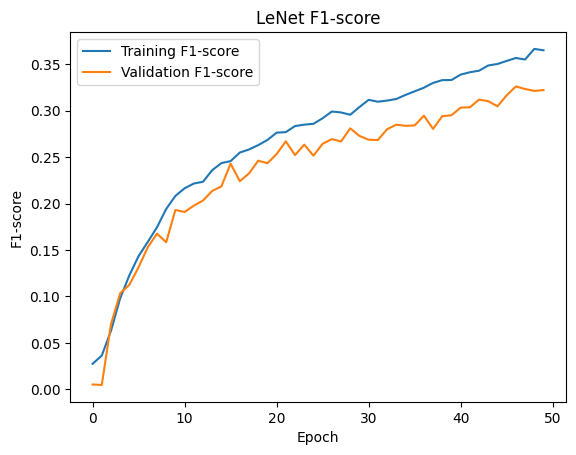

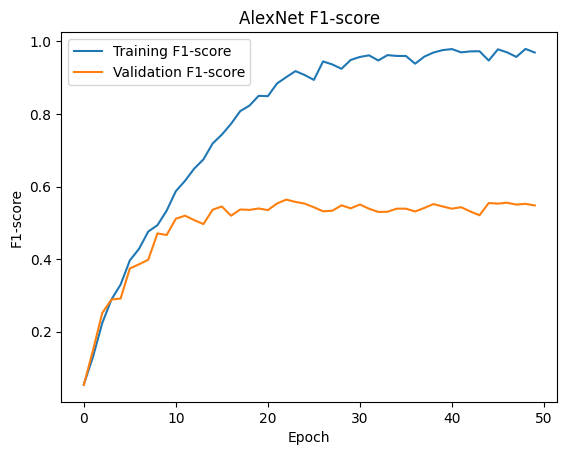

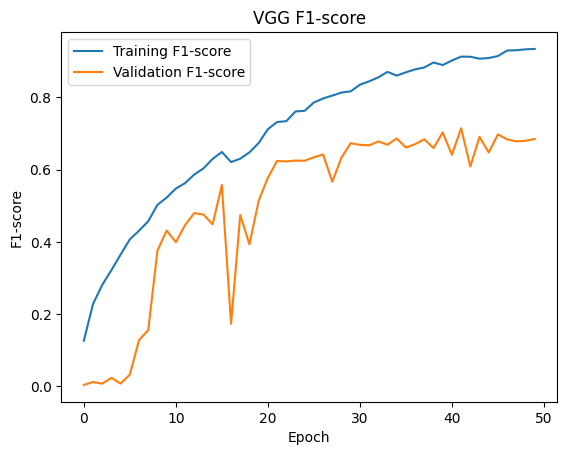

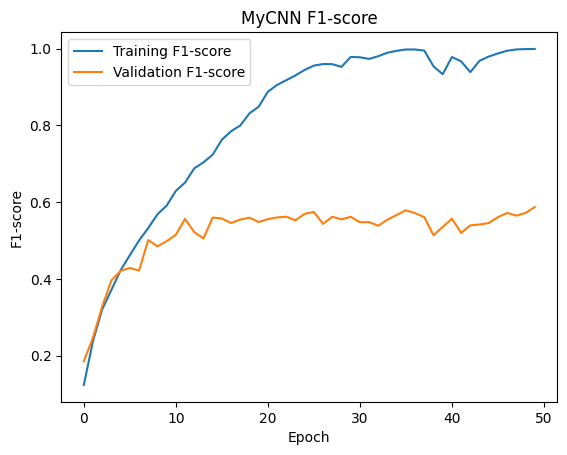

In [27]:
import matplotlib.pyplot as plt

# Function to plot F1 scores
def plot_f1_scores(history, model_name):
    plt.plot(history.history['f1_score'], label='Training F1-score')
    plt.plot(history.history['val_f1_score'], label='Validation F1-score')
    plt.title(f'{model_name} F1-score')
    plt.xlabel('Epoch')
    plt.ylabel('F1-score')
    plt.legend()
    plt.show()

# Plot F1 scores for LeNet
plot_f1_scores(LeNetHistory, 'LeNet')

 # Plot F1 scores for AlexNet
plot_f1_scores(AlexNetHistory, 'AlexNet')

# Plot F1 scores for VGG
plot_f1_scores(vggHistory, 'VGG')

# Plot F1 scores for MyCNN
plot_f1_scores(MyCNNHistory, 'MyCNN')



β. Αξιολογήστε, αναλυτικά, τα αποτελέσματά σας ως προς τα εξής:
 - Επίδραση του πλήθους των δεδομένων/κλάσεων.
 - Επίδραση του αλγόριθμου βελτιστοποίησης (optimizer)
 - Επίδραση του μεγέθους δέσμης (batch size)


Για να αξιολογήσουμε τα αποτελέσματα λεπτομερώς, ας εξετάσουμε τις επιπτώσεις του αριθμού δεδομένων/κλάσεων, του αλγόριθμου βελτιστοποίησης (βελτιστοποιητής) και του μεγέθους παρτίδας στην απόδοση των μοντέλων.

1. **Επίδραση του αριθμού δεδομένων/κλάσεων**:
    - **Αριθμός δεδομένων**: Η αύξηση του αριθμού των σημείων δεδομένων στο σύνολο εκπαίδευσης γενικά οδηγεί σε καλύτερη γενίκευση του μοντέλου. Με πιο διαφορετικά δεδομένα, το μοντέλο μπορεί να μάθει πιο αντιπροσωπευτικά χαρακτηριστικά και μοτίβα, τα οποία μπορούν να βελτιώσουν την ικανότητά του να γενικεύει σε μη ορατά δεδομένα. Ωστόσο, πέρα από ένα ορισμένο σημείο, η προσθήκη περισσότερων δεδομένων μπορεί να έχει μειωμένες αποδόσεις.
    - **Αριθμός κλάσεων**: Ο αριθμός των κλάσεων στο σύνολο δεδομένων επηρεάζει την πολυπλοκότητα της εργασίας ταξινόμησης. Με μεγαλύτερο αριθμό κλάσεων, το μοντέλο πρέπει να μάθει περισσότερα διακριτικά χαρακτηριστικά για να διακρίνει μεταξύ διαφορετικών κλάσεων. Αυτό μπορεί να κάνει τη διαδικασία εκπαίδευσης πιο προκλητική και μπορεί να απαιτήσει μεγαλύτερα μοντέλα ή περισσότερα δεδομένα για την επίτευξη καλής απόδοσης.


2. **Επίδραση του αλγόριθμου βελτιστοποίησης (Optimizer)**:
    - Η επιλογή του βελτιστοποιητή μπορεί να επηρεάσει σημαντικά τη δυναμική εκπαίδευσης και την τελική απόδοση του μοντέλου. Τα προγράμματα βελτιστοποίησης όπως τα SGD, Adam, RMSprop κ.λπ., έχουν διαφορετικούς κανόνες ενημέρωσης και συμπεριφορές σύγκλισης.
    - **SGD (Stochastic Gradient Descent)**: Απλό και ευρέως χρησιμοποιούμενο, το SGD ενημερώνει τις παραμέτρους στην αντίθετη κατεύθυνση της κλίσης της συνάρτησης απώλειας σε σχέση με τις παραμέτρους. Το SGD σαν optimizer είχε πολύ μειωμένες αποδόσεις.
    - **Adam (Adaptive Moment Estimation)**: Συνδυάζει ιδέες από την ορμή και το RMSprop. Προσαρμόζει τον ρυθμό εκμάθησης για κάθε παράμετρο, επιτρέποντας διαφορετικούς ρυθμούς εκμάθησης για διαφορετικές παραμέτρους.


3. **Επίδραση του μεγέθους παρτίδας**:

    - **Batch Size**: Πρόκειται για τον αριθμό των δειγμάτων που υποβλήθηκαν σε επεξεργασία πριν από την ενημέρωση των παραμέτρων του μοντέλου. Τα μεγαλύτερα μεγέθη παρτίδων παρατηρούμε ότι οδηγούν σε ταχύτερη σύγκλιση λόγω πιο σταθερών εκτιμήσεων κλίσης, αλλά μπορεί να απαιτούν περισσότερη μνήμη και υπολογιστικούς πόρους.
      
Αξιολογώντας τα μοντέλα υπό διαφορετικές συνθήκες και αναλύοντας τις μετρήσεις απόδοσής τους, όπως οι βαθμολογίες F1, η ακρίβεια και οι καμπύλες απωλειών, μπορούμε να αποκτήσουμε πληροφορίες για το πώς αυτοί οι παράγοντες επηρεάζουν την απόδοση του μοντέλου και να λάβουμε τεκμηριωμένες αποφάσεις κατά το σχεδιασμό και την εκπαίδευση μοντέλων βαθιάς μάθησης.

---

### Βήμα 3: Αξιολόγηση F1-score
Αξιολογήστε τα F1-scores, χρησιμοποιώντας το σύνολο ελέγχου σας (test set).

---

In [28]:
# Evaluate F1-scores for LeNet model
print("Evaluating F1-score for LeNet Model ...")
y_pred_lenet = LeNetModel.predict(x_test)
f1_score_lenet = f1_score(y_test_mapped, tf.argmax(y_pred_lenet, axis=1), average='macro')
print("F1-score for LeNet Model:", f1_score_lenet)

# Evaluate F1-scores for AlexNet model
print("Evaluating F1-score for AlexNet Model ...")
y_pred_alexnet = AlexNetModel.predict(x_test)
f1_score_alexnet = f1_score(y_test_mapped, tf.argmax(y_pred_alexnet, axis=1), average='macro')
print("F1-score for AlexNet Model:", f1_score_alexnet)

# Evaluate F1-scores for VGG model
print("Evaluating F1-score for VGG Model ...")
y_pred_vgg = vggmodel.predict(x_test)
f1_score_vgg = f1_score(y_test_mapped, tf.argmax(y_pred_vgg, axis=1), average='macro')
print("F1-score for VGG Model:", f1_score_vgg)

# Evaluate F1-scores for MyCNN model
print("Evaluating F1-score for MyCNN Model ...")
y_pred_mycnn = MyCNNModel.predict(x_test)
f1_score_mycnn = f1_score(y_test_mapped, tf.argmax(y_pred_mycnn, axis=1), average='macro')
print("F1-score for MyCNN Model:", f1_score_mycnn)


Evaluating F1-score for LeNet Model ...
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
F1-score for LeNet Model: 0.3476235545048167
Evaluating F1-score for AlexNet Model ...
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step
F1-score for AlexNet Model: 0.5609859414041644
Evaluating F1-score for VGG Model ...
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step
F1-score for VGG Model: 0.7137229000935709
Evaluating F1-score for MyCNN Model ...
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
F1-score for MyCNN Model: 0.597787379380638



## Ερώτημα 2
---
### Βήμα 1: Έλεγχος υπερεκπαίδευσης

Για μοντέλο σας  (**MyCNN**) και μόνο, δοκιμάστε διάφορους συνδυασμούς των ακόλουθων τεχνικών για τον έλεγχο της υπερεκπαίδευσης (overfitting), ώστε το μοντέλο σας να γενικεύει καλύτερα, όπως:

- Dropout ([Dropout](https://www.tensorflow.org/tutorials/images/classification#dropout))

- Επαύξηση δεδομένων ([Data augmentation](https://www.tensorflow.org/tutorials/images/classification#data_augmentation), [ImageDataGenerator](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator#class_imagedatagenerator))

---



In [36]:
def MyCNN1():
    model = tf.keras.models.Sequential([
        # Data augmentation
        layers.RandomFlip("horizontal", input_shape=(32, 32, 3)),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),

        # Convolutional layers
        tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'),
        tf.keras.layers.MaxPool2D(pool_size=2),

        tf.keras.layers.Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'),
        tf.keras.layers.MaxPool2D(pool_size=2),

        tf.keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
        tf.keras.layers.MaxPool2D(pool_size=2),

        tf.keras.layers.Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'),
        tf.keras.layers.MaxPool2D(pool_size=2),

        # Fully connected layers
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu'),
        #tf.keras.layers.Dropout(0.15),
        tf.keras.layers.Dense(64, activation='relu'),
        #tf.keras.layers.Dropout(0.15),

        # Output layer
        tf.keras.layers.Dense(20, activation='softmax')
    ])

    return model


In [37]:
# Define MyCNN model for 32x32x3 images
MyCNNModel_1 = MyCNN1()

# Print MyCNN Model Summary
print("MyCNN1 Model Summary:")
MyCNNModel_1.summary()

f1_score_metric = F1Score(average='macro') # You can adjust 'average' as per your requirement
# Compile the model with custom F1 score metric
MyCNNModel_1.compile(optimizer='adam',
                   loss='categorical_crossentropy',
                   metrics=[f1_score_metric])

y_train_mapped_onehot = to_categorical(y_train_mapped, classes_num)
y_val_mapped_onehot = to_categorical(y_val_mapped, classes_num)

print("Training MyCNN1 Model ...")
# Train the model
MyCNNHistory1 = MyCNNModel_1.fit(x_train, y_train_mapped_onehot,
                              batch_size=128,
                              epochs=50,
                              validation_data=(x_val, y_val_mapped_onehot),
                              verbose=1)


MyCNN1 Model Summary:


Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_5 (RandomFlip)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_5               │ (None, 32, 32, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_5 (RandomZoom)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_131 (Conv2D)             │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_71 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_132 (Conv2D)             │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_72 (MaxPooling2D) │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_133 (Conv2D)             │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_73 (MaxPooling2D) │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_134 (Conv2D)             │ (None, 3, 3, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_74 (MaxPooling2D) │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_20 (Flatten)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 254,548 (994.33 KB)

 Trainable params: 254,548 (994.33 KB)

 Non-trainable params: 0 (0.00 B)

Training MyCNN1 Model ...
Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - f1_score: 0.0444 - loss: 2.9052 - val_f1_score: 0.1165 - val_loss: 2.6064
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - f1_score: 0.1784 - loss: 2.4990 - val_f1_score: 0.2106 - val_loss: 2.3494
Epoch 3/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - f1_score: 0.2573 - loss: 2.2846 - val_f1_score: 0.2832 - val_loss: 2.2231
Epoch 4/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - f1_score: 0.3060 - loss: 2.1500 - val_f1_score: 0.3307 - val_loss: 2.0880
Epoch 5/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - f1_score: 0.3286 - loss: 2.0378 - val_f1_score: 0.3429 - val_loss: 2.0532
Epoch 6/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - f1_score: 0.3569 - loss: 1.9578 - val_f1_score: 0.3254 - val_loss: 2.0893
Epoch 7/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - f1_score: 0.3829 - loss: 1.8586 - val_f1_score: 0.4277 - val_loss: 1.8606
Epoch 8/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - f1_score: 0.4078 - loss: 1.8007 

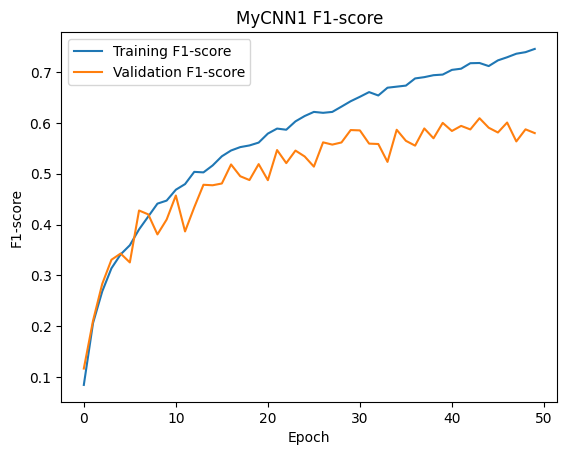

In [38]:
plot_f1_scores(MyCNNHistory1, 'MyCNN1')

In [39]:
def MyCNN2(input_shape, num_classes):
    model = models.Sequential([
        layers.Conv2D(32, kernel_size=3, activation='relu', input_shape=input_shape),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(128, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(128, kernel_size=3, activation='relu', padding='same'),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model


In [41]:
# Define MyCNN model for 32x32x3 images
MyCNNModel_2 = MyCNN2((32, 32, 3), classes_num)

# Print MyCNN Model Summary
print("MyCNN2 Model Summary:")
MyCNNModel_2.summary()

f1_score_metric = F1Score(average='macro') # You can adjust 'average' as per your requirement
# Compile the model with custom F1 score metric
MyCNNModel_2.compile(optimizer='adam',
                   loss='categorical_crossentropy',
                   metrics=[f1_score_metric])

y_train_mapped_onehot = to_categorical(y_train_mapped, classes_num)
y_val_mapped_onehot = to_categorical(y_val_mapped, classes_num)

print("Training MyCNN2 Model ...")
# Train the model
MyCNNHistory2 = MyCNNModel_2.fit(x_train, y_train_mapped_onehot,
                              batch_size=128,
                              epochs=50,
                              validation_data=(x_val, y_val_mapped_onehot),
                              verbose=1)


MyCNN2 Model Summary:


Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_139 (Conv2D)             │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_79 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_140 (Conv2D)             │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_80 (MaxPooling2D) │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_141 (Conv2D)             │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_81 (MaxPooling2D) │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_142 (Conv2D)             │ (None, 3, 3, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_82 (MaxPooling2D) │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_22 (Flatten)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_66 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_67 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_68 (Dense)                │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 254,548 (994.33 KB)

 Trainable params: 254,548 (994.33 KB)

 Non-trainable params: 0 (0.00 B)

Training MyCNN2 Model ...
Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 11s 83ms/step - f1_score: 0.0479 - loss: 2.9812 - val_f1_score: 0.0469 - val_loss: 2.8756
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - f1_score: 0.0786 - loss: 2.8614 - val_f1_score: 0.0636 - val_loss: 2.7529
Epoch 3/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - f1_score: 0.0946 - loss: 2.7697 - val_f1_score: 0.1359 - val_loss: 2.5876
Epoch 4/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - f1_score: 0.1347 - loss: 2.6477 - val_f1_score: 0.1544 - val_loss: 2.5210
Epoch 5/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - f1_score: 0.1684 - loss: 2.5348 - val_f1_score: 0.2067 - val_loss: 2.4173
Epoch 6/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - f1_score: 0.1911 - loss: 2.4481 - val_f1_score: 0.2705 - val_loss: 2.2700
Epoch 7/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - f1_score: 0.2381 - loss: 2.3302 - val_f1_score: 0.2643 - val_loss: 2.1499
Epoch 8/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - f1_score: 0.2522 - loss: 2.2537 - val_

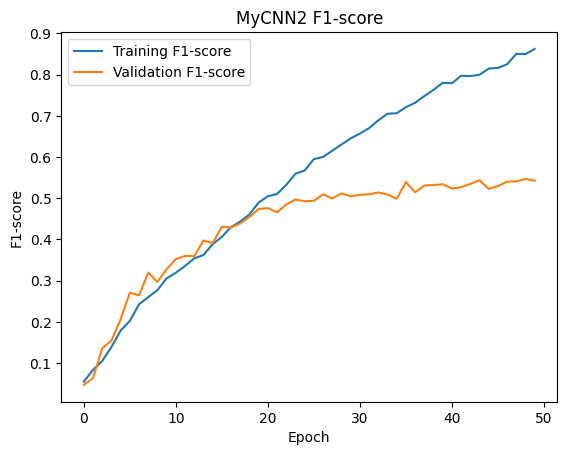

In [42]:
plot_f1_scores(MyCNNHistory2, 'MyCNN2')

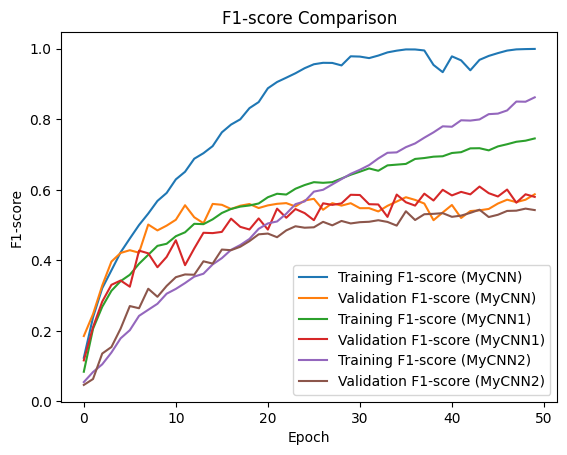

In [43]:
import matplotlib.pyplot as plt

def plot_f1_scores(history, model_name):
    plt.plot(history.history['f1_score'], label=f'Training F1-score ({model_name})')
    plt.plot(history.history['val_f1_score'], label=f'Validation F1-score ({model_name})')

# Assuming you have MyCNNHistory, MyCNNHistory1, MyCNNHistory2 variables containing training history for each model

# Plotting F1 scores for each model on the same plot
plot_f1_scores(MyCNNHistory, 'MyCNN')
plot_f1_scores(MyCNNHistory1, 'MyCNN1')
plot_f1_scores(MyCNNHistory2, 'MyCNN2')

plt.title('F1-score Comparison')
plt.xlabel('Epoch')
plt.ylabel('F1-score')
plt.legend()
plt.show()


### Βήμα 2: Αξιολόγηση
Αξιολογήστε τα αποτελέσματά σας, βάσει του F1 score για το σύνολο επικύρωσης και για το σύνολο ελέγχου

---

## Ερώτημα 3
---
### Βήμα 1: Μεταφορά γνώσης
Εφαρμόστε μεταφορά γνώσης (transfer learning) στο δικό σας μοντέλο (**MyCNN**), που αξιολογήσατε ως καλύτερο προς το F1 score στην αντιμετώπιση της υπερεκπαίδεσης.

Για το transfer learning, επιλέξτε το [VGG19](https://www.tensorflow.org/api_docs/python/tf/keras/applications/vgg19)  και το [EfficientNetB0](https://www.tensorflow.org/api_docs/python/tf/keras/applications/efficientnet/EfficientNetB0) για μεταφορά μάθησης.

α. "Παγώστε" τη συνελικτική βάση και εκπαιδεύστε την κεφαλή ταξινόμησης (classification head - σημαία trainable = False).  

β. Εκπαιδέστε μόνο ένα ποσοστό των επιπέδων, το οποίο βρίσκεται προς την έξοδο του δικτύου. Οι σημαίες trainable εδώ θα πρέπει να οριστούν ανά επίπεδο.



---
### Βήμα 2: Αξιολόγηση

Αξιολογήστε τα αποτελέσματά σας, βάσει του F1 score για το σύνολο επικύρωσης και για το σύνολο ελέγχου.

---

In [45]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19, EfficientNetB0
from tensorflow.keras.metrics import F1Score

# Define F1 score metric
f1_score_metric = F1Score(average='macro')

# Load pre-trained VGG19 model
vgg19_base = VGG19(weights='imagenet', include_top=False, input_shape=(32, 32, 3))
vgg19_base.trainable = False  # Freeze convolutional base

# Add classification head to VGG19 base
vgg19 = models.Sequential([
    vgg19_base,
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(classes_num, activation='softmax')
])

# Compile VGG19 model
vgg19.compile(optimizer='adam', loss='categorical_crossentropy', metrics=[f1_score_metric])

# Load pre-trained EfficientNetB0 model
effnet_base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(32, 32, 3))
effnet_base.trainable = False  # Freeze convolutional base

# Add classification head to EfficientNetB0 base
effnet_model = models.Sequential([
    effnet_base,
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(classes_num, activation='softmax')
])

# Compile EfficientNetB0 model
effnet_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=[f1_score_metric])

# Train and evaluate VGG19 model
print("Training VGG19 Model ...")
vgg19history = vgg19.fit(x_train, y_train_mapped_onehot,
                            batch_size=128,
                            epochs=50,
                            validation_data=(x_val, y_val_mapped_onehot),
                            verbose=1)

# Train and evaluate EfficientNetB0 model
print("Training EfficientNetB0 Model ...")
effnet_history = effnet_model.fit(x_train, y_train_mapped_onehot,
                                  batch_size=128,
                                  epochs=50,
                                  validation_data=(x_val, y_val_mapped_onehot),
                                  verbose=1)


Training VGG19 Model ...
Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 10s 105ms/step - f1_score: 0.1062 - loss: 2.9117 - val_f1_score: 0.3062 - val_loss: 2.3095
Epoch 2/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - f1_score: 0.2774 - loss: 2.3381 - val_f1_score: 0.4023 - val_loss: 1.9634
Epoch 3/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - f1_score: 0.3611 - loss: 2.0374 - val_f1_score: 0.4115 - val_loss: 1.8054
Epoch 4/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - f1_score: 0.3954 - loss: 1.9018 - val_f1_score: 0.4508 - val_loss: 1.7171
Epoch 5/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - f1_score: 0.4283 - loss: 1.8094 - val_f1_score: 0.4578 - val_loss: 1.6654
Epoch 6/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - f1_score: 0.4558 - loss: 1.7276 - val_f1_score: 0.4911 - val_loss: 1.6217
Epoch 7/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - f1_score: 0.4670 - loss: 1.6915 - val_f1_score: 0.5003 - val_loss: 1.5880
Epoch 8/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - f1_score: 0.4850 - loss: 1.6317

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - f1_score: 0.5505 - loss: 1.5017
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - f1_score: 0.0046 - loss: 2.9959
F1 Score for VGG19 Model: 0.5773192048072815
F1 Score for EfficientNetB0 Model: 0.00476190447807312


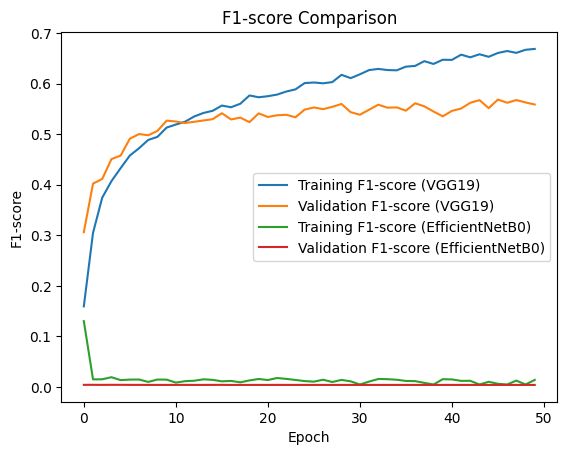

In [47]:
# Convert y_test_mapped to one-hot encoding
y_test_mapped_onehot = to_categorical(y_test_mapped, classes_num)

# Evaluate models on the test set
vgg19_score = vgg19.evaluate(x_test, y_test_mapped_onehot)[1]
effnet_score = effnet_model.evaluate(x_test, y_test_mapped_onehot)[1]

print("F1 Score for VGG19 Model:", vgg19_score)
print("F1 Score for EfficientNetB0 Model:", effnet_score)
plot_f1_scores(vgg19history, 'VGG19')
plot_f1_scores(effnet_history, 'EfficientNetB0')
plt.title('F1-score Comparison')
plt.xlabel('Epoch')
plt.ylabel('F1-score')
plt.legend()
plt.show()

## Διαχείριση μνήμης (TFRecord)
Η φόρτωση δεδομένων με τον τρόπο που το κάναμε παραπάνω στο απλό παράδειγμα υλοποίησης είναι πολύ βολική αλλά δεν είναι αποτελεσματική ως προς τη διαχείριση της μνήμης. Συγκεκριμένα, με τον τρόπο αυτό, τα δεδομένα αποθηκεύονται απευθείας σε μεταβλητές, οι οποίες όλες μαζί καταλαμβάνουν τη RAM της CPU ή της GPU, κάτι που κάνει αδύνατη τη διαχείριση μεγάλων datasets ή τον μεταχηματισμό των δεδομένων όπως όταν κάνουμε αύξηση δεδομένων (data augmentation).

Για να παρακαμφθεί αυτό το πρόβλημα, υπάρχει η δυνατότητα της σειριοποίησης των δεδομένων (serialization) και της αποθήκευσής τους σε αρχεία μεσαίου μεγέθους (κάποιων MB) τα οποία μπορούν να αναγνωστούν γραμμικά.

Το φορμάτ TFRecord είναι ένα φορμάτ που επιτρέπει την αποθήκευση σειράς δυαδικών εγγραφών. Διαβάστε σχετικά για το [TFRecord and tf.Example](https://www.tensorflow.org/tutorials/load_data/tfrecord) και [tf.data: Build TensorFlow input pipelines](https://www.tensorflow.org/guide/data).

Σημειώστε ότι με τη μέθοδο αυτή θα πρέπει να γίνει import η `tensorflow_datasets` και να χρησιμοποιήσουμε την `tfds.load` ώστε να αποθηκευθεί το σύνολο δεδομένων σε αρχεία tfrecord στο δίσκο (δείτε [εδώ](https://colab.research.google.com/github/tensorflow/datasets/blob/master/docs/overview.ipynb) ένα παράδειγμα). Φυσικά μπορούμε να μετατρέψουμε και τα πρωτογενή δεδομένα (raw data) του dataset όπως αρχεία jpg σε φορματ tfrecord όπως [εδώ](https://towardsdatascience.com/working-with-tfrecords-and-tf-train-example-36d111b3ff4d).
